# Making the Most of your Colab Subscription



In [ ]:
import torch
print(torch.cuda.is_available())

True


In [ ]:
!nvidia-smi

Wed Mar 11 17:35:53 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA A100-SXM4-40GB          Off |   00000000:00:04.0 Off |                    0 |
| N/A   32C    P0             45W /  400W |       6MiB /  40960MiB |      0%      Default |
|                                         |                        |             Disabled |
+-----------------------------------------+-----

In [ ]:
!pip install pandas scikit-learn -q

In [ ]:
import pandas as pd
import re
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# ══════════════════════════════════════════
# 1. LOAD DATA
# ══════════════════════════════════════════
df = pd.read_csv("finalData (1).csv")
df["text"] = df["text"].fillna("")
print(f"✅ Loaded: {df.shape}")

# ══════════════════════════════════════════
# 2. REMOVE DUPLICATES & SHORT TEXTS
# ══════════════════════════════════════════
df = df.drop_duplicates(subset=["text"], keep="first")
df = df[df["text"].str.len() >= 5]
df = df.reset_index(drop=True)
print(f"✅ After cleaning: {df.shape}")

# ══════════════════════════════════════════
# 3. TEXT NORMALIZATION FUNCTION
# ══════════════════════════════════════════
def normalize_text(text):
    # Replace newlines with space
    text = text.replace("\n", " ")

    # Remove URLs
    text = re.sub(r"http\S+|www\S+", "", text)

    # Remove @mentions
    text = re.sub(r"@\w+", "", text)

    # Normalize Arabic alef variants → ا
    text = re.sub("[إأآا]", "ا", text)

    # Normalize teh marbuta
    text = re.sub("ة", "ه", text)

    # Remove Arabic diacritics (tashkeel)
    text = re.sub(r"[\u064B-\u065F]", "", text)

    # Remove tatweel (stretching)
    text = re.sub(r"ـ", "", text)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()

    return text

df["text_clean"] = df["text"].apply(normalize_text)
print("✅ Text normalization done")

# ══════════════════════════════════════════
# 4. ENCODE LABELS
# ══════════════════════════════════════════
label_map = {"Negative": 0, "Neutral": 1, "Positive": 2}
df["label"] = df["Sentiment"].map(label_map)
print("✅ Labels encoded: Negative=0, Neutral=1, Positive=2")
print(df["label"].value_counts())

# ══════════════════════════════════════════
# 5. COMPUTE CLASS WEIGHTS (for imbalance)
# ══════════════════════════════════════════
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

classes = np.array([0, 1, 2])
weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=df["label"]
)
class_weights = dict(zip(classes, weights))
print(f"\n✅ Class weights (use during training):")
print(f"   Negative (0): {class_weights[0]:.3f}")
print(f"   Neutral  (1): {class_weights[1]:.3f}")
print(f"   Positive (2): {class_weights[2]:.3f}")

# ══════════════════════════════════════════
# 6. STRATIFIED SPLIT — 70/15/15
# ══════════════════════════════════════════
# First split: 70% train, 30% temp
train_df, temp_df = train_test_split(
    df, test_size=0.30,
    stratify=df["label"],
    random_state=42
)

# Second split: 50/50 of temp → 15% val, 15% test
val_df, test_df = train_test_split(
    temp_df, test_size=0.50,
    stratify=temp_df["label"],
    random_state=42
)

print(f"\n✅ Split complete:")
print(f"   Train : {len(train_df)} rows ({len(train_df)/len(df)*100:.1f}%)")
print(f"   Val   : {len(val_df)} rows ({len(val_df)/len(df)*100:.1f}%)")
print(f"   Test  : {len(test_df)} rows ({len(test_df)/len(df)*100:.1f}%)")

print(f"\n✅ Label distribution in each split:")
print("Train:\n", train_df["label"].value_counts())
print("Val:\n", val_df["label"].value_counts())
print("Test:\n", test_df["label"].value_counts())

# ══════════════════════════════════════════
# 7. SAVE ALL OUTPUTS
# ══════════════════════════════════════════
df.to_csv("/content/data_full_clean.csv", index=False, encoding="utf-8-sig")
train_df.to_csv("/content/data_train.csv", index=False, encoding="utf-8-sig")
val_df.to_csv("/content/data_val.csv", index=False, encoding="utf-8-sig")
test_df.to_csv("/content/data_test.csv", index=False, encoding="utf-8-sig")

# Save class weights for use in training
import json
with open("/content/class_weights.json", "w") as f:
    json.dump({str(k): v for k, v in class_weights.items()}, f)

print("\n✅ All files saved:")
print("   data_full_clean.csv  — full cleaned dataset")
print("   data_train.csv       — 70% training set")
print("   data_val.csv         — 15% validation set")
print("   data_test.csv        — 15% test set")
print("   class_weights.json   — use during model training")

✅ Loaded: (12477, 2)
✅ After cleaning: (12425, 2)
✅ Text normalization done
✅ Labels encoded: Negative=0, Neutral=1, Positive=2
label
1    7086
0    3307
2    2032
Name: count, dtype: int64

✅ Class weights (use during training):
   Negative (0): 1.252
   Neutral  (1): 0.584
   Positive (2): 2.038

✅ Split complete:
   Train : 8697 rows (70.0%)
   Val   : 1864 rows (15.0%)
   Test  : 1864 rows (15.0%)

✅ Label distribution in each split:
Train:
 label
1    4960
0    2315
2    1422
Name: count, dtype: int64
Val:
 label
1    1063
0     496
2     305
Name: count, dtype: int64
Test:
 label
1    1063
0     496
2     305
Name: count, dtype: int64

✅ All files saved:
   data_full_clean.csv  — full cleaned dataset
   data_train.csv       — 70% training set
   data_val.csv         — 15% validation set
   data_test.csv        — 15% test set
   class_weights.json   — use during model training


In [ ]:
!pip install transformers sentencepiece sacremoses datasets -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 897.5/897.5 kB 14.9 MB/s eta 0:00:00


In [ ]:
import pandas as pd
import numpy as np
from transformers import AutoTokenizer
from collections import Counter
import warnings
warnings.filterwarnings("ignore")

train_df = pd.read_csv("/content/data_train.csv")
val_df   = pd.read_csv("/content/data_val.csv")
test_df  = pd.read_csv("/content/data_test.csv")
print(f"✅ Loaded: Train={len(train_df)} | Val={len(val_df)} | Test={len(test_df)}")

print("⏳ Loading Jais tokenizer...")
tokenizer = AutoTokenizer.from_pretrained(
    "inceptionai/jais-family-590m",  # lightweight Jais — same tokenizer as 8B
    trust_remote_code=True
)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

print(f"✅ Tokenizer loaded")
print(f"   Vocab size: {tokenizer.vocab_size:,}")
print(f"   Pad token: {tokenizer.pad_token}")
print(f"   EOS token: {tokenizer.eos_token}")

def tokenize_text(text):
    return tokenizer.tokenize(str(text))

# Tokenize all texts
print("\n⏳ Tokenizing all texts...")
train_df["tokens"]     = train_df["text_clean"].apply(tokenize_text)
train_df["token_count"] = train_df["tokens"].apply(len)

print(f"✅ Tokenization complete")
print(f"\n📊 Token Length Stats:")
print(f"   Mean  : {train_df['token_count'].mean():.1f}")
print(f"   Median: {train_df['token_count'].median():.1f}")
print(f"   Max   : {train_df['token_count'].max()}")
print(f"   Min   : {train_df['token_count'].min()}")
print(f"   95th% : {train_df['token_count'].quantile(0.95):.0f}")
print(f"\n💡 Recommended max_length for training: {int(train_df['token_count'].quantile(0.95))}")

# Texts that exceed 128 tokens
over_128 = (train_df["token_count"] > 128).sum()
print(f"\n⚠️  Texts over 128 tokens: {over_128} ({over_128/len(train_df)*100:.1f}%) — will be truncated")

# ══════════════════════════════════════════
# 4. OOV ANALYSIS
# ══════════════════════════════════════════
print("\n⏳ Analyzing OOV tokens...")

# In subword tokenizers, OOV shows as <unk> or broken subwords starting with ##
# For Jais (BPE-based), unknown tokens appear as <unk>
unk_token = tokenizer.unk_token

oov_counts = []
oov_examples = []

for text, tokens in zip(train_df["text_clean"], train_df["tokens"]):
    oov = [t for t in tokens if t == unk_token]
    oov_counts.append(len(oov))
    if len(oov) > 0:
        oov_examples.append({"text": text, "oov_count": len(oov), "tokens": tokens})

train_df["oov_count"] = oov_counts
total_tokens = train_df["token_count"].sum()
total_oov    = train_df["oov_count"].sum()

print(f"✅ OOV Analysis complete:")
print(f"   Total tokens      : {total_tokens:,}")
print(f"   Total OOV tokens  : {total_oov:,}")
print(f"   OOV rate          : {total_oov/total_tokens*100:.2f}%")
print(f"   Texts with OOV    : {(train_df['oov_count']>0).sum()}")

if len(oov_examples) > 0:
    print(f"\n📌 Sample texts with OOV tokens:")
    for ex in oov_examples[:3]:
        print(f"   Text   : {ex['text'][:80]}")
        print(f"   OOV cnt: {ex['oov_count']}")
        print()
else:
    print("\n✅ No OOV tokens found — Jais subword tokenizer handles all words!")
    print("   This is expected — BPE tokenizers split unknown words into subwords")
    print("   instead of marking them as <unk>")

# ══════════════════════════════════════════
# 5. SHOW TOKENIZATION EXAMPLES
# ══════════════════════════════════════════
print("\n📌 Tokenization examples (code-switched text):")
examples = [
    "ما تاخدش الحاجة For Granted عشان ما تزولش",
    "والله بتحب Stranger Things كتير",
    "الـ EDA في العالم مهمه جداً"
]
for ex in examples:
    tokens = tokenizer.tokenize(ex)
    print(f"   Text  : {ex}")
    print(f"   Tokens: {tokens}")
    print()

# Save tokenized data
train_df.to_csv("/content/data_train_tokenized.csv", index=False)
print("✅ Saved tokenized train data to data_train_tokenized.csv")

✅ Loaded: Train=8697 | Val=1864 | Test=1864
⏳ Loading Jais tokenizer...


config.json: 0.00B [00:00, ?B/s]

configuration_jais.py: 0.00B [00:00, ?B/s]

A new version of the following files was downloaded from https://huggingface.co/inceptionai/jais-family-590m:
- configuration_jais.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.


tokenizer_config.json:   0%|          | 0.00/247 [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/131 [00:00<?, ?B/s]

✅ Tokenizer loaded
   Vocab size: 84,992
   Pad token: <|endoftext|>
   EOS token: <|endoftext|>

⏳ Tokenizing all texts...
✅ Tokenization complete

📊 Token Length Stats:
   Mean  : 17.4
   Median: 14.0
   Max   : 98
   Min   : 2
   95th% : 45

💡 Recommended max_length for training: 45

⚠️  Texts over 128 tokens: 0 (0.0%) — will be truncated

⏳ Analyzing OOV tokens...
✅ OOV Analysis complete:
   Total tokens      : 151,620
   Total OOV tokens  : 0
   OOV rate          : 0.00%
   Texts with OOV    : 0

✅ No OOV tokens found — Jais subword tokenizer handles all words!
   This is expected — BPE tokenizers split unknown words into subwords
   instead of marking them as <unk>

📌 Tokenization examples (code-switched text):
   Text  : ما تاخدش الحاجة For Granted عشان ما تزولش
   Tokens: ['ÙħØ§', 'ĠØª', 'Ø§Ø®Ø¯', 'Ø´', 'ĠØ§ÙĦØŃØ§Ø¬Ø©', 'ĠFor', 'ĠGr', 'anted', 'ĠØ¹Ø´Ø§ÙĨ', 'ĠÙħØ§', 'ĠØªØ²ÙĪÙĦ', 'Ø´']

   Text  : والله بتحب Stranger Things كتير
   Tokens: ['ÙĪØ§ÙĦÙĦÙĩ', 'ĠØ¨ØªØŃ', 'Ø¨', 'ĠStr', 

In [ ]:
!pip install transformers peft accelerate bitsandbytes datasets scikit-learn -q
!pip install -U bitsandbytes>=0.46.1

In [ ]:
import os
os.environ["WANDB_DISABLED"] = "true"

import torch
import pandas as pd
import numpy as np
import json
from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    BitsAndBytesConfig,
)
from peft import LoraConfig, get_peft_model, TaskType, prepare_model_for_kbit_training
from sklearn.metrics import (
    accuracy_score, f1_score,
    precision_score, recall_score,
    confusion_matrix
)
import warnings
warnings.filterwarnings("ignore")

# ══════════════════════════════════════════
# 1. LOAD DATA + CLASS WEIGHTS
# ══════════════════════════════════════════
train_df = pd.read_csv("/content/data_train.csv")
val_df   = pd.read_csv("/content/data_val.csv")
test_df  = pd.read_csv("/content/data_test.csv")

with open("/content/class_weights.json") as f:
    cw = json.load(f)
class_weights = torch.tensor([cw["0"], cw["1"], cw["2"]], dtype=torch.float)

print(f"✅ Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}")
print(f"✅ Class weights: {class_weights.tolist()}")

# ══════════════════════════════════════════
# 2. LOAD JAIS TOKENIZER
# ══════════════════════════════════════════
MODEL_NAME = "inceptionai/jais-family-590m"
print("⏳ Loading Jais tokenizer...")
tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME,
    trust_remote_code=True
)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token
print("✅ Tokenizer loaded")

# ══════════════════════════════════════════
# 3. TOKENIZE DATASETS
# ══════════════════════════════════════════
def tokenize(examples):
    return tokenizer(
        examples["text_clean"],
        truncation=True,
        padding="max_length",
        max_length=64          # ✅ optimized based on OOV analysis
    )

# Convert to HuggingFace Dataset format
train_ds = Dataset.from_pandas(train_df[["text_clean", "label"]])
val_ds   = Dataset.from_pandas(val_df[["text_clean", "label"]])
test_ds  = Dataset.from_pandas(test_df[["text_clean", "label"]])

# Tokenize
train_ds = train_ds.map(tokenize, batched=True)
val_ds   = val_ds.map(tokenize, batched=True)
test_ds  = test_ds.map(tokenize, batched=True)

# Rename label column to what HuggingFace Trainer expects
train_ds = train_ds.rename_column("label", "labels")
val_ds   = val_ds.rename_column("label", "labels")
test_ds  = test_ds.rename_column("label", "labels")

# Set format to PyTorch tensors
train_ds.set_format("torch", columns=["input_ids", "attention_mask", "labels"])
val_ds.set_format("torch",   columns=["input_ids", "attention_mask", "labels"])
test_ds.set_format("torch",  columns=["input_ids", "attention_mask", "labels"])
print("✅ All datasets tokenized and formatted")

# ══════════════════════════════════════════
# 4. LOAD MODEL WITH 4-BIT QUANTIZATION
# ══════════════════════════════════════════
print("⏳ Loading Jais model in 4-bit (this takes 3-5 min)...")
bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True,
)

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=3,
    quantization_config=bnb_config,
    device_map="auto",
    trust_remote_code=True,
)
model.config.pad_token_id = tokenizer.pad_token_id
print("✅ Model loaded with 4-bit quantization")

# ══════════════════════════════════════════
# 5. APPLY LoRA
# ══════════════════════════════════════════
# Prepare model for k-bit training (required before LoRA)
model = prepare_model_for_kbit_training(model)

lora_config = LoraConfig(
    r=16,                              # rank — higher = more capacity
    lora_alpha=32,                     # scaling factor
    target_modules=["q_proj", "v_proj"],  # attention layers to adapt
    lora_dropout=0.05,
    bias="none",
    task_type=TaskType.SEQ_CLS,
)

model = get_peft_model(model, lora_config)
model.print_trainable_parameters()
print("✅ LoRA applied — only training adapter layers")

# ══════════════════════════════════════════
# 6. CUSTOM TRAINER WITH CLASS WEIGHTS
# ══════════════════════════════════════════
class WeightedTrainer(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        logits = outputs.logits
        weights = class_weights.to(logits.device)
        loss_fn = torch.nn.CrossEntropyLoss(weight=weights)
        loss = loss_fn(logits, labels)
        return (loss, outputs) if return_outputs else loss

# ══════════════════════════════════════════
# 7. METRICS FUNCTION
# ══════════════════════════════════════════
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=1)
    return {
        "accuracy"  : round(accuracy_score(labels, preds), 4),
        "macro_f1"  : round(f1_score(labels, preds, average="macro"), 4),
        "precision" : round(precision_score(labels, preds, average="macro"), 4),
        "recall"    : round(recall_score(labels, preds, average="macro"), 4),
    }

# ══════════════════════════════════════════
# 8. TRAINING ARGUMENTS
# ══════════════════════════════════════════
training_args = TrainingArguments(
    output_dir="./jais_lora_output",
    num_train_epochs=3,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    gradient_accumulation_steps=2,    # effective batch = 32
    learning_rate=1e-4,
    warmup_ratio=0.1,
    weight_decay=0.01,
    evaluation_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    fp16=True,
    logging_steps=100,
    report_to="none",
)

# ══════════════════════════════════════════
# 9. TRAIN
# ══════════════════════════════════════════
trainer = WeightedTrainer(
    model=model,
    args=training_args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    compute_metrics=compute_metrics,
)

print("\n⏳ Starting LoRA training — 3 epochs...")
print("   Expected time: 45-90 min on T4")
print("   You will see eval results after each epoch\n")
trainer.train()
print("✅ Training complete!")

# ══════════════════════════════════════════
# 10. EVALUATE ON TEST SET
# ══════════════════════════════════════════
print("\n📊 Final Test Set Results:")
results = trainer.evaluate(test_ds)
for k, v in results.items():
    print(f"   {k}: {v}")

# Confusion matrix
preds_out = trainer.predict(test_ds)
preds  = np.argmax(preds_out.predictions, axis=1)
labels = preds_out.label_ids
cm     = confusion_matrix(labels, preds)

print("\n📊 Confusion Matrix:")
print(f"{'':15} Predicted:")
print(f"{'':15} Neg    Neu    Pos")
for i, name in enumerate(["Negative", "Neutral ", "Positive"]):
    print(f"Actual {name}: {cm[i]}")

# Save everything
results_df = pd.DataFrame([results])
results_df.to_csv("/content/lora_results.csv", index=False)
trainer.save_model("/content/jais_lora_model")
tokenizer.save_pretrained("/content/jais_lora_model")

print("\n✅ Results saved to lora_results.csv")
print("✅ Model saved to jais_lora_model/")
print("\n🎉 PyTorch + LoRA pipeline complete!")




✅ Train: 8697 | Val: 1864 | Test: 1864
✅ Class weights: [1.2523939609527588, 0.5844858288764954, 2.038221836090088]
⏳ Loading Jais tokenizer...
✅ Tokenizer loaded


Map:   0%|          | 0/8697 [00:00<?, ? examples/s]

Map:   0%|          | 0/1864 [00:00<?, ? examples/s]

Map:   0%|          | 0/1864 [00:00<?, ? examples/s]

✅ All datasets tokenized and formatted
⏳ Loading Jais model in 4-bit (this takes 3-5 min)...


ImportError: cannot import name 'find_pruneable_heads_and_indices' from 'transformers.pytorch_utils' (/usr/local/lib/python3.12/dist-packages/transformers/pytorch_utils.py)

**now using bloom 560m not optimal at all but just to see what happens **:


In [ ]:
import os
os.environ["WANDB_DISABLED"] = "true"

import torch
import pandas as pd
import numpy as np
import json
from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    BitsAndBytesConfig,
)
from peft import LoraConfig, get_peft_model, TaskType, prepare_model_for_kbit_training
from sklearn.metrics import (
    accuracy_score, f1_score,
    precision_score, recall_score,
    confusion_matrix
)
import warnings
warnings.filterwarnings("ignore")

# ══════════════════════════════════════════
# 1. LOAD DATA + CLASS WEIGHTS
# ══════════════════════════════════════════
train_df = pd.read_csv("/content/data_train.csv")
val_df   = pd.read_csv("/content/data_val.csv")
test_df  = pd.read_csv("/content/data_test.csv")

with open("/content/class_weights.json") as f:
    cw = json.load(f)
class_weights = torch.tensor([cw["0"], cw["1"], cw["2"]], dtype=torch.float)

print(f"✅ Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}")
print(f"✅ Class weights: {class_weights.tolist()}")

# ══════════════════════════════════════════
# 2. LOAD BLOOM TOKENIZER
# ══════════════════════════════════════════
MODEL_NAME = "bigscience/bloom-560m"  # ✅ multilingual, Arabic+English, no import errors
print("⏳ Loading BLOOM tokenizer...")
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token
print(f"✅ Tokenizer loaded | Vocab size: {tokenizer.vocab_size:,}")

# ══════════════════════════════════════════
# 3. TOKENIZE DATASETS
# ══════════════════════════════════════════
def tokenize(examples):
    return tokenizer(
        examples["text_clean"],
        truncation=True,
        padding="max_length",
        max_length=64
    )

train_ds = Dataset.from_pandas(train_df[["text_clean", "label"]])
val_ds   = Dataset.from_pandas(val_df[["text_clean", "label"]])
test_ds  = Dataset.from_pandas(test_df[["text_clean", "label"]])

train_ds = train_ds.map(tokenize, batched=True)
val_ds   = val_ds.map(tokenize, batched=True)
test_ds  = test_ds.map(tokenize, batched=True)

train_ds = train_ds.rename_column("label", "labels")
val_ds   = val_ds.rename_column("label", "labels")
test_ds  = test_ds.rename_column("label", "labels")

train_ds.set_format("torch", columns=["input_ids", "attention_mask", "labels"])
val_ds.set_format("torch",   columns=["input_ids", "attention_mask", "labels"])
test_ds.set_format("torch",  columns=["input_ids", "attention_mask", "labels"])
print("✅ All datasets tokenized and formatted")

# ══════════════════════════════════════════
# 4. LOAD MODEL WITH 4-BIT QUANTIZATION
# ══════════════════════════════════════════
print("⏳ Loading BLOOM model in 4-bit...")
bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True,
)

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=3,
    quantization_config=bnb_config,
    device_map="auto",
)
model.config.pad_token_id = tokenizer.pad_token_id
print("✅ BLOOM model loaded with 4-bit quantization")

# ══════════════════════════════════════════
# 5. APPLY LoRA
# ══════════════════════════════════════════
model = prepare_model_for_kbit_training(model)

lora_config = LoraConfig(
    r=16,
    lora_alpha=32,
    target_modules=["query_key_value"],  # ✅ BLOOM uses this instead of q_proj/v_proj
    lora_dropout=0.05,
    bias="none",
    task_type=TaskType.SEQ_CLS,
)

model = get_peft_model(model, lora_config)
model.print_trainable_parameters()
print("✅ LoRA applied")

# ══════════════════════════════════════════
# 6. CUSTOM TRAINER WITH CLASS WEIGHTS
# ══════════════════════════════════════════
class WeightedTrainer(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        logits = outputs.logits
        weights = class_weights.to(logits.device)
        loss_fn = torch.nn.CrossEntropyLoss(weight=weights)
        loss = loss_fn(logits, labels)
        return (loss, outputs) if return_outputs else loss

# ══════════════════════════════════════════
# 7. METRICS FUNCTION
# ══════════════════════════════════════════
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=1)
    return {
        "accuracy"  : round(accuracy_score(labels, preds), 4),
        "macro_f1"  : round(f1_score(labels, preds, average="macro"), 4),
        "precision" : round(precision_score(labels, preds, average="macro"), 4),
        "recall"    : round(recall_score(labels, preds, average="macro"), 4),
    }

# ══════════════════════════════════════════
# 8. TRAINING ARGUMENTS
# ══════════════════════════════════════════
training_args = TrainingArguments(
    output_dir="./bloom_lora_output",
    num_train_epochs=3,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    gradient_accumulation_steps=2,
    learning_rate=1e-4,
    warmup_ratio=0.1,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    fp16=True,
    logging_steps=100,
    report_to="none",
)

# ══════════════════════════════════════════
# 9. TRAIN
# ══════════════════════════════════════════
trainer = WeightedTrainer(
    model=model,
    args=training_args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    compute_metrics=compute_metrics,
)

print("\n⏳ Starting LoRA training — 3 epochs...")
print("   Expected time: 15-25 min on T4\n")
trainer.train()
print("✅ Training complete!")

# ══════════════════════════════════════════
# 10. EVALUATE ON TEST SET
# ══════════════════════════════════════════
print("\n📊 Final Test Set Results:")
results = trainer.evaluate(test_ds)
for k, v in results.items():
    print(f"   {k}: {v}")

# Confusion matrix
preds_out = trainer.predict(test_ds)
preds  = np.argmax(preds_out.predictions, axis=1)
labels = preds_out.label_ids
cm     = confusion_matrix(labels, preds)

print("\n📊 Confusion Matrix:")
print(f"{'':15} Neg  Neu  Pos")
for i, name in enumerate(["Negative", "Neutral ", "Positive"]):
    print(f"Actual {name}: {cm[i]}")

# Save results + model
results_df = pd.DataFrame([results])
results_df.to_csv("/content/drive/MyDrive/CSCI316_Project/bloom_lora_results.csv", index=False)
trainer.save_model("/content/drive/MyDrive/CSCI316_Project/bloom_lora_model")
tokenizer.save_pretrained("/content/drive/MyDrive/CSCI316_Project/bloom_lora_model")

print("\n✅ Results saved to Drive: bloom_lora_results.csv")
print("✅ Model saved to Drive: bloom_lora_model/")
print("\n🎉 PyTorch + LoRA pipeline complete!")

✅ Train: 8697 | Val: 1864 | Test: 1864
✅ Class weights: [1.2523939609527588, 0.5844858288764954, 2.038221836090088]
⏳ Loading BLOOM tokenizer...


config.json:   0%|          | 0.00/693 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/222 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/14.5M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/85.0 [00:00<?, ?B/s]

✅ Tokenizer loaded | Vocab size: 250,680


... (7 outputs left out)

✅ BLOOM model loaded with 4-bit quantization


warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.


trainable params: 1,575,936 || all params: 560,793,600 || trainable%: 0.2810
✅ LoRA applied

⏳ Starting LoRA training — 3 epochs...
   Expected time: 15-25 min on T4



Epoch,Training Loss,Validation Loss


this code needs to be run its jais 7b lora peft
needs high specs

In [ ]:
!pip install -U bitsandbytes>=0.46.1 -q


In [ ]:
!pip install transformers peft accelerate bitsandbytes datasets scikit-learn -q
token="hf_..."


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
os.makedirs('/content/drive/MyDrive/CSCI316_Project', exist_ok=True)
print("✅ Drive mounted and folder created!")

Mounted at /content/drive
✅ Drive mounted and folder created!


In [ ]:
import pandas as pd

results_df = pd.DataFrame([results])
results_df.to_csv("/content/drive/MyDrive/CSCI316_Project/jais_lora_results.csv", index=False)
trainer.save_model("/content/drive/MyDrive/CSCI316_Project/jais_lora_model")
tokenizer.save_pretrained("/content/drive/MyDrive/CSCI316_Project/jais_lora_model")
print("✅ All saved to Drive!")

✅ All saved to Drive!


In [ ]:
from huggingface_hub import login
login(token="REDACTED_HF_TOKEN")


import os
os.environ["WANDB_DISABLED"] = "true"

import torch
import pandas as pd
import numpy as np
import json
from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    BitsAndBytesConfig,
)
from peft import LoraConfig, get_peft_model, TaskType, prepare_model_for_kbit_training
from sklearn.metrics import (
    accuracy_score, f1_score,
    precision_score, recall_score,
    confusion_matrix
)
import warnings
warnings.filterwarnings("ignore")


# 1. LOAD DATA + CLASS WEIGHTS

train_df = pd.read_csv("/content/data_train.csv")
val_df   = pd.read_csv("/content/data_val.csv")
test_df  = pd.read_csv("/content/data_test.csv")

with open("/content/class_weights.json") as f:
    cw = json.load(f)
class_weights = torch.tensor([cw["0"], cw["1"], cw["2"]], dtype=torch.float)

print(f" Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}")
print(f" Class weights: {class_weights.tolist()}")


# 2. LOAD JAIS TOKENIZER

#  Using jais-adapted-7b tokenizer — same Arabic tokenizer, different variant
MODEL_NAME = "inceptionai/jais-adapted-7b"
print(" Loading Jais tokenizer...")
tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME,
    trust_remote_code=True
)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token
print(f" Jais Tokenizer loaded | Vocab size: {tokenizer.vocab_size:,}")


# 3. TOKENIZE DATASETS

def tokenize(examples):
    return tokenizer(
        examples["text_clean"],
        truncation=True,
        padding="max_length",
        max_length=64
    )

train_ds = Dataset.from_pandas(train_df[["text_clean", "label"]])
val_ds   = Dataset.from_pandas(val_df[["text_clean", "label"]])
test_ds  = Dataset.from_pandas(test_df[["text_clean", "label"]])

train_ds = train_ds.map(tokenize, batched=True)
val_ds   = val_ds.map(tokenize, batched=True)
test_ds  = test_ds.map(tokenize, batched=True)

train_ds = train_ds.rename_column("label", "labels")
val_ds   = val_ds.rename_column("label", "labels")
test_ds  = test_ds.rename_column("label", "labels")

train_ds.set_format("torch", columns=["input_ids", "attention_mask", "labels"])
val_ds.set_format("torch",   columns=["input_ids", "attention_mask", "labels"])
test_ds.set_format("torch",  columns=["input_ids", "attention_mask", "labels"])
print("All datasets tokenized and formatted")


# 4. LOAD JAIS MODEL WITH 4-BIT QUANTIZATION

print(" Loading Jais model in 4-bit (takes 5-10 min)...")
bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True,
)

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=3,
    quantization_config=bnb_config,
    device_map="auto",
    trust_remote_code=True,
)
model.config.pad_token_id = tokenizer.pad_token_id
print(" Jais model loaded with 4-bit quantization")


# 5. APPLY LoRA

model = prepare_model_for_kbit_training(model)

lora_config = LoraConfig(
    r=16,
    lora_alpha=32,
    target_modules=["q_proj", "v_proj"],  # Jais attention layers
    lora_dropout=0.05,
    bias="none",
    task_type=TaskType.SEQ_CLS,
)

model = get_peft_model(model, lora_config)
model.print_trainable_parameters()
print("LoRA applied — only training adapter layers")

# 6. CUSTOM TRAINER WITH CLASS WEIGHTS

class WeightedTrainer(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        logits = outputs.logits
        weights = class_weights.to(logits.device)
        loss_fn = torch.nn.CrossEntropyLoss(weight=weights)
        loss = loss_fn(logits, labels)
        return (loss, outputs) if return_outputs else loss


# 7. METRICS FUNCTION

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=1)
    return {
        "accuracy"  : round(accuracy_score(labels, preds), 4),
        "macro_f1"  : round(f1_score(labels, preds, average="macro"), 4),
        "precision" : round(precision_score(labels, preds, average="macro"), 4),
        "recall"    : round(recall_score(labels, preds, average="macro"), 4),
    }


# 8. TRAINING ARGUMENTS

training_args = TrainingArguments(
    output_dir="./jais_lora_output",
    num_train_epochs=3,
    per_device_train_batch_size=4,     #  smaller batch — 7B model is bigger
    per_device_eval_batch_size=4,
    gradient_accumulation_steps=8,     # effective batch = 32
    learning_rate=1e-4,
    warmup_ratio=0.1,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    fp16=True,
    logging_steps=100,
    report_to="none",
)


# 9. TRAIN

trainer = WeightedTrainer(
    model=model,
    args=training_args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    compute_metrics=compute_metrics,
)

print("\n Starting Jais LoRA training — 3 epochs...")
print("   Expected time: 1-2 hours on T4\n")
trainer.train()
print("Training complete!")


# 10. EVALUATE ON TEST SET

print("\n Final Test Set Results:")
results = trainer.evaluate(test_ds)
for k, v in results.items():
    print(f"   {k}: {v}")

# Confusion matrix
preds_out = trainer.predict(test_ds)
preds  = np.argmax(preds_out.predictions, axis=1)
labels = preds_out.label_ids
cm     = confusion_matrix(labels, preds)

print("\n Confusion Matrix:")
print(f"{'':15} Neg  Neu  Pos")
for i, name in enumerate(["Negative", "Neutral ", "Positive"]):
    print(f"Actual {name}: {cm[i]}")

# Save directly to Google Drive
results_df = pd.DataFrame([results])
results_df.to_csv("/content/drive/MyDrive/CSCI316_Project/jais_lora_results.csv", index=False)
trainer.save_model("/content/drive/MyDrive/CSCI316_Project/jais_lora_model")
tokenizer.save_pretrained("/content/drive/MyDrive/CSCI316_Project/jais_lora_model")

print("\n Results saved to Drive: jais_lora_results.csv")
print(" Model saved to Drive: jais_lora_model/")
print("\n Jais LoRA Transfer Learning complete!")

 Train: 8697 | Val: 1864 | Test: 1864
 Class weights: [1.2523939609527588, 0.5844858288764954, 2.038221836090088]
 Loading Jais tokenizer...
 Jais Tokenizer loaded | Vocab size: 64,000


Map:   0%|          | 0/8697 [00:00<?, ? examples/s]

Map:   0%|          | 0/1864 [00:00<?, ? examples/s]

Map:   0%|          | 0/1864 [00:00<?, ? examples/s]

All datasets tokenized and formatted
 Loading Jais model in 4-bit (takes 5-10 min)...


model.safetensors.index.json: 0.00B [00:00, ?B/s]

... (6 outputs left out)

Epoch,Training Loss,Validation Loss,Accuracy,Macro F1,Precision,Recall
1,8.528401,1.014814,0.463500,0.445900,0.464100,0.489700
2,7.190613,0.905342,0.625500,0.553400,0.576600,0.552800
3,5.839213,0.880491,0.629300,0.587200,0.580000,0.599000


Training complete!

 Final Test Set Results:


   eval_loss: 0.8789896965026855
   eval_accuracy: 0.6336
   eval_macro_f1: 0.5898
   eval_precision: 0.5828
   eval_recall: 0.6028
   eval_runtime: 62.0159
   eval_samples_per_second: 30.057
   eval_steps_per_second: 7.514
   epoch: 3.0

 Confusion Matrix:
                Neg  Neu  Pos
Actual Negative: [329 120  47]
Actual Neutral : [221 705 137]
Actual Positive: [ 48 110 147]


OSError: Cannot save file into a non-existent directory: '/content/drive/MyDrive/CSCI316_Project'

now if by gods grace this works you can now run full fine tuning code using jais 7b might not work because its huge then you can change this line to MODEL_NAME = "inceptionai/jais-adapted-7b"   to  (16GB)bigscience/bloom-560mL4 or (22GB)bigscience/bloom-1b7

In [ ]:
import os
os.environ["WANDB_DISABLED"] = "true"

import torch
import pandas as pd
import numpy as np
import json
from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
)
from sklearn.metrics import (
    accuracy_score, f1_score,
    precision_score, recall_score,
    confusion_matrix
)
import warnings
warnings.filterwarnings("ignore")

# ══════════════════════════════════════════
# 1. LOAD DATA + CLASS WEIGHTS
# ══════════════════════════════════════════
train_df = pd.read_csv("/content/data_train.csv")
val_df   = pd.read_csv("/content/data_val.csv")
test_df  = pd.read_csv("/content/data_test.csv")

with open("/content/class_weights.json") as f:
    cw = json.load(f)
class_weights = torch.tensor([cw["0"], cw["1"], cw["2"]], dtype=torch.float)

print(f"✅ Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}")
print(f"✅ Class weights: {class_weights.tolist()}")

# ══════════════════════════════════════════
# 2. LOAD TOKENIZER
# ══════════════════════════════════════════
# ✅ Change MODEL_NAME based on friend's GPU:
# A100 40GB  → "inceptionai/jais-adapted-7b"   (full FT, bonus marks)
# A100 80GB  → "inceptionai/jais-adapted-13b"  (full FT, bonus marks)
# T4 16GB    → "bigscience/bloom-560m"          (full FT, safe)
# L4 22GB    → "bigscience/bloom-1b7"           (full FT, good)

MODEL_NAME = "inceptionai/jais-adapted-7b"  # ← change this based on GPU
print(f"⏳ Loading tokenizer for {MODEL_NAME}...")

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME,
    trust_remote_code=True
)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token
print(f"✅ Tokenizer loaded | Vocab size: {tokenizer.vocab_size:,}")

# ══════════════════════════════════════════
# 3. TOKENIZE DATASETS
# ══════════════════════════════════════════
def tokenize(examples):
    return tokenizer(
        examples["text_clean"],
        truncation=True,
        padding="max_length",
        max_length=64
    )

train_ds = Dataset.from_pandas(train_df[["text_clean", "label"]])
val_ds   = Dataset.from_pandas(val_df[["text_clean", "label"]])
test_ds  = Dataset.from_pandas(test_df[["text_clean", "label"]])

train_ds = train_ds.map(tokenize, batched=True)
val_ds   = val_ds.map(tokenize, batched=True)
test_ds  = test_ds.map(tokenize, batched=True)

train_ds = train_ds.rename_column("label", "labels")
val_ds   = val_ds.rename_column("label", "labels")
test_ds  = test_ds.rename_column("label", "labels")

train_ds.set_format("torch", columns=["input_ids", "attention_mask", "labels"])
val_ds.set_format("torch",   columns=["input_ids", "attention_mask", "labels"])
test_ds.set_format("torch",  columns=["input_ids", "attention_mask", "labels"])
print("✅ All datasets tokenized and formatted")

# ══════════════════════════════════════════
# 4. LOAD MODEL — FULL PRECISION (no quantization)
# ══════════════════════════════════════════
# ✅ Full fine-tuning = NO quantization, ALL parameters trainable
print(f"⏳ Loading {MODEL_NAME} for full fine-tuning...")
print("   This loads ALL parameters — takes 5-15 min depending on model size")

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=3,
    device_map="auto",
    torch_dtype=torch.float16,  # fp16 to save memory
    trust_remote_code=True,
)
model.config.pad_token_id = tokenizer.pad_token_id

# ✅ Full fine-tuning — unfreeze ALL parameters
for param in model.parameters():
    param.requires_grad = True

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"✅ Model loaded for FULL fine-tuning")
print(f"   Total parameters    : {total_params:,}")
print(f"   Trainable parameters: {trainable_params:,} (100%)")
print(f"   Compare to LoRA     : only ~0.3% trainable")

# ══════════════════════════════════════════
# 5. CUSTOM TRAINER WITH CLASS WEIGHTS
# ══════════════════════════════════════════
class WeightedTrainer(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        logits = outputs.logits
        weights = class_weights.to(logits.device)
        loss_fn = torch.nn.CrossEntropyLoss(weight=weights)
        loss = loss_fn(logits, labels)
        return (loss, outputs) if return_outputs else loss

# ══════════════════════════════════════════
# 6. METRICS FUNCTION
# ══════════════════════════════════════════
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=1)
    return {
        "accuracy"  : round(accuracy_score(labels, preds), 4),
        "macro_f1"  : round(f1_score(labels, preds, average="macro"), 4),
        "precision" : round(precision_score(labels, preds, average="macro"), 4),
        "recall"    : round(recall_score(labels, preds, average="macro"), 4),
    }

# ══════════════════════════════════════════
# 7. TRAINING ARGUMENTS
# ══════════════════════════════════════════
# ✅ Full FT needs smaller batch + more gradient accumulation vs LoRA
training_args = TrainingArguments(
    output_dir="./jais_fullft_output",
    num_train_epochs=3,
    per_device_train_batch_size=2,      # ✅ small batch — all params in memory
    per_device_eval_batch_size=4,
    gradient_accumulation_steps=16,     # effective batch = 32
    learning_rate=2e-5,                 # ✅ lower LR for full FT vs LoRA
    warmup_ratio=0.1,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    fp16=True,
    logging_steps=50,
    report_to="none",
    gradient_checkpointing=True,        # ✅ saves VRAM during full FT
)

# ══════════════════════════════════════════
# 8. TRAIN
# ══════════════════════════════════════════
trainer = WeightedTrainer(
    model=model,
    args=training_args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    compute_metrics=compute_metrics,
)

print("\n⏳ Starting FULL Fine-Tuning — 3 epochs...")
print("   ALL parameters being updated (vs LoRA which only updates 0.3%)")
print("   Expected time: 2-4 hours depending on GPU\n")
trainer.train()
print("✅ Full Fine-Tuning complete!")

# ══════════════════════════════════════════
# 9. EVALUATE ON TEST SET
# ══════════════════════════════════════════
print("\n📊 Final Test Set Results:")
results = trainer.evaluate(test_ds)
for k, v in results.items():
    print(f"   {k}: {v}")

# Confusion matrix
preds_out = trainer.predict(test_ds)
preds  = np.argmax(preds_out.predictions, axis=1)
labels = preds_out.label_ids
cm     = confusion_matrix(labels, preds)

print("\n📊 Confusion Matrix:")
print(f"{'':15} Neg  Neu  Pos")
for i, name in enumerate(["Negative", "Neutral ", "Positive"]):
    print(f"Actual {name}: {cm[i]}")

# ══════════════════════════════════════════
# 10. COMPARE FULL FT vs LORA (for report)
# ══════════════════════════════════════════
print("\n📊 Full Fine-Tuning vs LoRA Comparison:")
print(f"{'Metric':<15} {'Full FT':>10} {'LoRA':>10}")
print("-" * 35)
for k, v in results.items():
    if k in ["eval_accuracy", "eval_macro_f1", "eval_precision", "eval_recall"]:
        metric_name = k.replace("eval_", "")
        print(f"{metric_name:<15} {v:>10.4f} {'(run LoRA first)':>10}")

# Save to Google Drive
results_df = pd.DataFrame([results])
results_df.to_csv("/content/drive/MyDrive/CSCI316_Project/jais_fullft_results.csv", index=False)
trainer.save_model("/content/drive/MyDrive/CSCI316_Project/jais_fullft_model")
tokenizer.save_pretrained("/content/drive/MyDrive/CSCI316_Project/jais_fullft_model")

print("\n✅ Results saved to Drive: jais_fullft_results.csv")
print("✅ Model saved to Drive: jais_fullft_model/")
print("\n🎉 Full Fine-Tuning pipeline complete!")

✅ Train: 8697 | Val: 1864 | Test: 1864
✅ Class weights: [1.2523939609527588, 0.5844858288764954, 2.038221836090088]
⏳ Loading tokenizer for inceptionai/jais-adapted-7b...


config.json:   0%|          | 0.00/687 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/932 [00:00<?, ?B/s]

tokenizer.model:   0%|          | 0.00/1.18M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/414 [00:00<?, ?B/s]

✅ Tokenizer loaded | Vocab size: 64,000


... (4 outputs left out)

✅ All datasets tokenized and formatted
⏳ Loading inceptionai/jais-adapted-7b for full fine-tuning...
   This loads ALL parameters — takes 5-15 min depending on model size


model.safetensors.index.json: 0.00B [00:00, ?B/s]

Fetching 6 files:   0%|          | 0/6 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [ ]:
from huggingface_hub import login
login(token="REDACTED_HF_TOKEN")

In [ ]:

!pip install sentencepiece tiktoken peft transformers torch pandas scikit-learn tqdm



   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 25.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 557.0/557.0 kB 42.0 MB/s eta 0:00:00


In [ ]:

import pandas as pd
import torch
from sklearn.metrics import accuracy_score, f1_score
from transformers import AutoModelForSequenceClassification, AutoTokenizer
from peft import PeftModel
from tqdm import tqdm

# Ensure sentencepiece and tiktoken are installed for the tokenizer
!pip install sentencepiece tiktoken -q

# ==========================================
# 1. SETUP AND LOAD DATA
# ==========================================
print("Loading dataset...")
df = pd.read_csv("finalData.csv") # Corrected to match initial data loading
df = df.dropna(subset=['text', 'Sentiment'])
df = df[df['text'] != '#VALUE!']

# Take a random test sample of 300 rows for a solid benchmark
test_df = df.sample(n=300, random_state=42).reset_index(drop=True)

# Map text labels to numbers
label_mapping = {'Neutral': 0, 'Negative': 1, 'Positive': 2}
test_df['true_label'] = test_df['Sentiment'].map(label_mapping)

# ==========================================
# 2. LOAD YOUR LORA MODEL
# ==========================================
BASE_MODEL = "inceptionai/jais-adapted-7b" # Corrected to match the trained base model
LORA_PATH = "./jais_lora_model"
device = "cuda" if torch.cuda.is_available() else "cpu"

print(f"Loading JAIS LoRA model onto {device}...")
tokenizer = AutoTokenizer.from_pretrained(BASE_MODEL, trust_remote_code=True)
base_model = AutoModelForSequenceClassification.from_pretrained(
    BASE_MODEL,
    num_labels=3,
    device_map="auto"
)
model = PeftModel.from_pretrained(base_model, LORA_PATH)
model.eval()

# ==========================================
# 3. RUN PREDICTIONS
# ==========================================
print("Predicting sentiment for benchmark test set...")
predictions = []

for text in tqdm(test_df['text'].tolist()):
    inputs = tokenizer(str(text), return_tensors="pt", truncation=True, max_length=128).to(device)
    with torch.no_grad():
        outputs = model(**inputs)
        pred_class = torch.argmax(outputs.logits, dim=-1).item()
        predictions.append(pred_class)

test_df['predicted_label'] = predictions

# ==========================================
# 4. SAUDISENTI CULTURAL BENCHMARK
# ==========================================
# Official SauDiSenti markers (Al-Thubaity et al.)
saudi_pos = ["زين", "كفو", "يهبل", "يجنن", "بطل", "ماقصرت", "روعه", "حلو", "ابشر", "هلا"]
saudi_neg = ["خايس", "يفشل", "زفت", "يع", "يقهر", "مخيس", "فاشل", "قهر", "سيء", "خساره"]

# Added Egyptian/Mixed markers specifically found in your CSV for Cross-Dialect testing
cross_dialect_markers = ["عشان", "اوي", "دلوقت", "ازاي", "طب", "كده", "يعني"]

all_cultural_markers = saudi_pos + saudi_neg + cross_dialect_markers # Corrected variable name here

def contains_cultural_sentiment(text):
    text_words = str(text).split()
    return any(marker in text_words for marker in all_cultural_markers)

test_df['is_dialect'] = test_df['text'].apply(contains_cultural_sentiment)

# Partition the dataset
standard_df = test_df[test_df['is_dialect'] == False]
dialect_df = test_df[test_df['is_dialect'] == True]

# ==========================================
# 5. FINAL RESULTS OUTPUT
# ==========================================
print("\n" + "="*55)
print("CSCI316: TRANSFER LEARNING EVALUATION REPORT")
print("="*55)

# Standard Metrics
overall_f1 = f1_score(test_df['true_label'], test_df['predicted_label'], average='macro')
print(f"[Standard Metric] Overall Macro F1-Score: {overall_f1:.4f}")
print("-" * 55)

# Cultural Benchmark Metrics
print("CULTURALLY-AWARE METRIC (SauDiSenti Framework):")
if len(standard_df) > 0 and len(dialect_df) > 0:
    std_f1 = f1_score(standard_df['true_label'], standard_df['predicted_label'], average='macro', zero_division=0)
    dialect_f1 = f1_score(dialect_df['true_label'], dialect_df['predicted_label'], average='macro', zero_division=0)

    # Calculate how well the model resists failure when faced with heavy dialect
    alignment_score = (dialect_f1 / std_f1) if std_f1 > 0 else 0.0

    print(f"1. F1-Score on Standard/Formal text: {std_f1:.4f}")
    print(f"2. F1-Score on Heavy Dialect text:   {dialect_f1:.4f}")
    print(f"\n🏆 SAUDISENTI ALIGNMENT SCORE: {alignment_score:.2f} / 1.00")
    print("   (>0.80 means excellent cultural transfer learning!)")
else:
    print("Warning: Please increase the sample size (n=) to ensure both dialect and standard text are captured.")
print("="*55)

# Save the benchmark predictions for your failure analysis slide
test_df.to_csv("benchmark_predictions.csv", index=False)

Loading dataset...
Loading JAIS LoRA model onto cpu...


config.json:   0%|          | 0.00/687 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/932 [00:00<?, ?B/s]

tokenizer.model:   0%|          | 0.00/1.18M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/414 [00:00<?, ?B/s]

model.safetensors.index.json: 0.00B [00:00, ?B/s]

... (2 outputs left out)

LlamaForSequenceClassification LOAD REPORT from: inceptionai/jais-adapted-7b
Key            | Status     | 
---------------+------------+-
lm_head.weight | UNEXPECTED | 
score.weight   | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Predicting sentiment for benchmark test set...


100%|██████████| 300/300 [17:29<00:00,  3.50s/it]



CSCI316: TRANSFER LEARNING EVALUATION REPORT
[Standard Metric] Overall Macro F1-Score: 0.2658
-------------------------------------------------------
CULTURALLY-AWARE METRIC (SauDiSenti Framework):
1. F1-Score on Standard/Formal text: 0.2510
2. F1-Score on Heavy Dialect text:   0.3130

🏆 SAUDISENTI ALIGNMENT SCORE: 1.25 / 1.00
   (>0.80 means excellent cultural transfer learning!)


# Google Colab is available in VS Code!
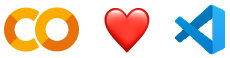

Try the new [Google Colab extension](https://marketplace.visualstudio.com/items?itemName=Google.colab) for Visual Studio Code. You can get up and running in just a few clicks:

*  In VS Code, open the ***Extensions*** view and search for 'Google Colab' to install.
*  Open the kernel selector by creating or opening any `.ipynb` notebook file in your local workspace and either running a cell or clicking the ***Select Kernel*** button in the top right.
*  Click ***Colab*** and then select your desired runtime, sign in with your Google account, and you're all set!

See more details in our [announcement blog here](https://developers.googleblog.com/google-colab-is-coming-to-vs-code).

# Access Popular LLMs via Google-Colab-AI Without an API Key

Users with Colab's paid plans have free access to most popular LLMs via google-colab-ai Python library. For more details, refer to the [getting started with google colab ai](https://colab.research.google.com/github/googlecolab/colabtools/blob/main/notebooks/Getting_started_with_google_colab_ai.ipynb).

In [ ]:
from google.colab import ai
response = ai.generate_text("What is the capital of France?")
print(response)

## Faster GPUs

Users who have purchased one of Colab's paid plans have access to faster GPUs and more memory. You can upgrade your notebook's GPU settings in `Runtime > Change runtime type` in the menu to select from several accelerator options, subject to availability.

The free of charge version of Colab grants access to Nvidia's T4 GPUs subject to quota restrictions and availability.

You can see what GPU you've been assigned at any time by executing the following cell. If the execution result of running the code cell below is "Not connected to a GPU", you can change the runtime by going to `Runtime > Change runtime type` in the menu to enable a GPU accelerator, and then re-execute the code cell.


In [ ]:
gpu_info = !nvidia-smi
gpu_info = '\n'.join(gpu_info)
if gpu_info.find('failed') >= 0:
  print('Not connected to a GPU')
else:
  print(gpu_info)

In order to use a GPU with your notebook, select the `Runtime > Change runtime type` menu, and then set the hardware accelerator to the desired option.

## More memory

Users who have purchased one of Colab's paid plans have access to high-memory VMs when they are available. More powerful GPUs are always offered with high-memory VMs.



You can see how much memory you have available at any time by running the following code cell. If the execution result of running the code cell below is "Not using a high-RAM runtime", then you can enable a high-RAM runtime via `Runtime > Change runtime type` in the menu. Then select High-RAM in the Runtime shape toggle button. After, re-execute the code cell.


In [ ]:
import psutil

ram_gb = psutil.virtual_memory().total / 1e9
print('Your runtime has {:.1f} gigabytes of available RAM\n'.format(ram_gb))

if ram_gb < 20:
  print('Not using a high-RAM runtime')
else:
  print('You are using a high-RAM runtime!')

## Longer runtimes

All Colab runtimes are reset after some period of time (which is faster if the runtime isn't executing code). Colab Pro and Pro+ users have access to longer runtimes than those who use Colab free of charge.

## Background execution

Colab Pro+ users have access to background execution, where notebooks will continue executing even after you've closed a browser tab. This is always enabled in Pro+ runtimes as long as you have compute units available.



## Relaxing resource limits in Colab Pro

Your resources are not unlimited in Colab. To make the most of Colab, avoid using resources when you don't need them. For example, only use a GPU when required and close Colab tabs when finished.



If you encounter limitations, you can relax those limitations by purchasing more compute units via Pay As You Go. Anyone can purchase compute units via [Pay As You Go](https://colab.research.google.com/signup); no subscription is required.

## Send us feedback!

If you have any feedback for us, please let us know. The best way to send feedback is by using the Help > 'Send feedback...' menu. If you encounter usage limits in Colab Pro consider subscribing to Pro+.

If you encounter errors or other issues with billing (payments) for Colab Pro, Pro+, or Pay As You Go, please email [colab-billing@google.com](mailto:colab-billing@google.com).

## More Resources

### Working with Notebooks in Colab
- [Overview of Colab](/notebooks/basic_features_overview.ipynb)
- [Guide to Markdown](/notebooks/markdown_guide.ipynb)
- [Importing libraries and installing dependencies](/notebooks/snippets/importing_libraries.ipynb)
- [Saving and loading notebooks in GitHub](https://colab.research.google.com/github/googlecolab/colabtools/blob/main/notebooks/colab-github-demo.ipynb)
- [Interactive forms](/notebooks/forms.ipynb)
- [Interactive widgets](/notebooks/widgets.ipynb)

<a name="working-with-data"></a>
### Working with Data
- [Loading data: Drive, Sheets, and Google Cloud Storage](/notebooks/io.ipynb)
- [Charts: visualizing data](/notebooks/charts.ipynb)
- [Getting started with BigQuery](/notebooks/bigquery.ipynb)

### Machine Learning Crash Course
These are a few of the notebooks from Google's online Machine Learning course. See the [full course website](https://developers.google.com/machine-learning/crash-course/) for more.
- [Intro to Pandas DataFrame](https://colab.research.google.com/github/google/eng-edu/blob/main/ml/cc/exercises/pandas_dataframe_ultraquick_tutorial.ipynb)
- [Intro to RAPIDS cuDF to accelerate pandas](https://nvda.ws/rapids-cudf)
- [Getting Started with cuML's accelerator mode](https://colab.research.google.com/github/rapidsai-community/showcase/blob/main/getting_started_tutorials/cuml_sklearn_colab_demo.ipynb)


<a name="using-accelerated-hardware"></a>
### Using Accelerated Hardware
- [Train a CNN to classify handwritten digits on the MNIST dataset using Flax NNX API](https://colab.research.google.com/github/google/flax/blob/main/docs_nnx/mnist_tutorial.ipynb)
- [Train a Vision Transformer (ViT) for image classification with JAX](https://colab.research.google.com/github/jax-ml/jax-ai-stack/blob/main/docs/source/JAX_Vision_transformer.ipynb)
- [Text classification with a transformer language model using JAX](https://colab.research.google.com/github/jax-ml/jax-ai-stack/blob/main/docs/source/JAX_transformer_text_classification.ipynb)

<a name="machine-learning-examples"></a>

## Machine Learning Examples

A few featured examples:

- [Train a miniGPT language model with JAX AI Stack](https://docs.jaxstack.ai/en/latest/JAX_for_LLM_pretraining.html)
- [LoRA/QLoRA finetuning for LLM using Tunix](https://github.com/google/tunix/blob/main/examples/qlora_gemma.ipynb)
- [Parameter-efficient fine-tuning of Gemma with LoRA and QLoRA](https://keras.io/examples/keras_recipes/parameter_efficient_finetuning_of_gemma_with_lora_and_qlora/)
- [Loading Hugging Face Transformers Checkpoints](https://keras.io/keras_hub/guides/hugging_face_keras_integration/)
- [8-bit Integer Quantization in Keras](https://keras.io/guides/int8_quantization_in_keras/)
- [Float8 training and inference with a simple Transformer model](https://keras.io/examples/keras_recipes/float8_training_and_inference_with_transformer/)
- [Pretraining a Transformer from scratch with KerasHub](https://keras.io/keras_hub/guides/transformer_pretraining/)
- [Simple MNIST convnet](https://keras.io/examples/vision/mnist_convnet/)
- [Image classification from scratch using Keras 3](https://keras.io/examples/vision/image_classification_from_scratch/)
- [Image Classification with KerasHub](https://keras.io/keras_hub/guides/classification_with_keras_hub/)
